In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from scipy.cluster.hierarchy import dendrogram,linkage
import matplotlib.pyplot as math
from sklearn.cluster import KMeans

mall = pd.read_csv("mall_customers.csv")

mall

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [4]:
mall.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

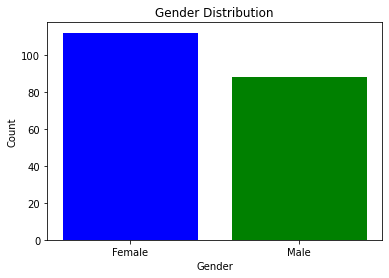

In [5]:
gender_counts = mall["Genre"].value_counts()
math.bar(gender_counts.index, gender_counts.values, color=['blue', 'green'])
math.xlabel('Gender')
math.ylabel('Count')
math.title('Gender Distribution')
math.show()


In [6]:
le = LabelEncoder()

mall["Genre"] = le.fit_transform(mall["Genre"])

In [7]:
mall

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40
...,...,...,...,...,...
195,196,0,35,120,79
196,197,0,45,126,28
197,198,1,32,126,74
198,199,1,32,137,18


In [8]:
model1 = KMeans(3,random_state=0)
model1 = model1.fit(mall[["Annual Income (k$)", "Spending Score (1-100)"]])
model1.cluster_centers_

array([[44.15447154, 49.82926829],
       [86.53846154, 82.12820513],
       [87.        , 18.63157895]])

In [9]:
model1.predict([[131,84],[267,45]])

/home/student/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1, 2], dtype=int32)

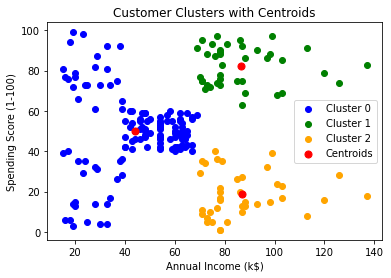

In [31]:
for i in range(model1.n_clusters):
    math.scatter(
        mall.loc[model1.labels_ == i, "Annual Income (k$)"],
        mall.loc[model1.labels_ == i, "Spending Score (1-100)"],
        c=colors[i],
        label=f'Cluster {i}'
    )

# Centroids
centers = model1.cluster_centers_

math.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='o',
    s=50,
    label='Centroids'
)

math.title('Customer Clusters with Centroids')
math.xlabel('Annual Income (k$)')
math.ylabel('Spending Score (1-100)')
math.legend()

math.show()

In [23]:
wcss = {}
for i in range(1,11):
    model3 = KMeans(i,random_state=0).fit(mall[["Annual Income (k$)", "Spending Score (1-100)"]])
    wcss[i] = model3.inertia_

print(wcss)

k,v = [],[]

for key,val in wcss.items():
    k.append(key)
    v.append(val)

{1: 269981.28, 2: 185917.14253928524, 3: 106348.37306211119, 4: 73679.78903948834, 5: 44448.45544793371, 6: 38858.9599751439, 7: 31969.426550235476, 8: 29858.483597603947, 9: 22209.851608025547, 10: 20786.93669205916}


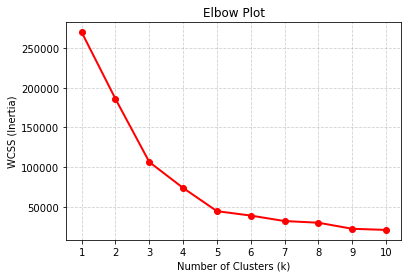

In [24]:
math.plot(k, v, marker='o', linewidth=2, color='red')
math.xticks(range(1, 11))

math.title('Elbow Plot')
math.xlabel('Number of Clusters (k)')
math.ylabel('WCSS (Inertia)')

math.grid(True, linestyle='--', alpha=0.6)
math.show()


In [25]:
#From the graph we can say that K(optimal) = 5

model2 = KMeans(5,random_state=0)
model2 = model2.fit(mall[["Annual Income (k$)", "Spending Score (1-100)"]])
model2.cluster_centers_

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348],
       [25.72727273, 79.36363636]])

In [26]:
model2.predict([[131,84],[267,45]])

/home/student/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1, 2], dtype=int32)

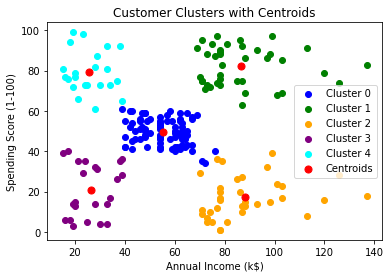

In [32]:
for i in range(model2.n_clusters):
    math.scatter(
        mall.loc[model2.labels_ == i, "Annual Income (k$)"],
        mall.loc[model2.labels_ == i, "Spending Score (1-100)"],
        c=colors[i],
        label=f'Cluster {i}'
    )

# Centroids
centers = model2.cluster_centers_

math.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='o',
    s=50,
    label='Centroids'
)

math.title('Customer Clusters with Centroids')
math.xlabel('Annual Income (k$)')
math.ylabel('Spending Score (1-100)')
math.legend()

math.show()

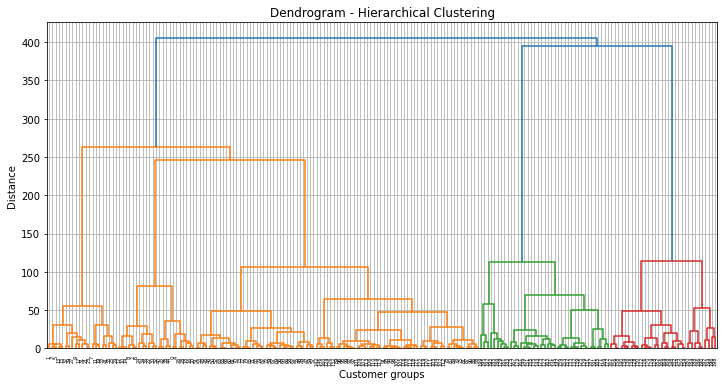

In [33]:
from scipy.cluster.hierarchy import linkage, dendrogram
import seaborn as sns

Z = linkage(mall[["Annual Income (k$)", "Spending Score (1-100)"]], method="ward")

math.figure(figsize=(12, 6))
dendrogram(Z)

math.title("Dendrogram - Hierarchical Clustering")
math.xlabel("Customer groups")
math.ylabel("Distance")
math.grid()
math.show()

In [35]:
personal = {"c_id": int(input("Enter customer ID: ")),
           "gender": (input("Enter gender(M/F): ")),
           "age": int(input("Enter age: "))}

financial = {"Annual Income (k$)": int(input("Enter Annual Income(k$): ")),
           "Spending Score (1-100)": int(input("Enter Spending Score(1-100): "))}

user_frame = pd.DataFrame([financial])

predicted = model2.predict(user_frame)

print(f"{personal} {financial}\nPredicted Catergorie: {predicted}")

Enter customer ID: 54
Enter gender(M/F): M
Enter age: 23
Enter Annual Income(k$): 35
Enter Spending Score(1-100): 67
{'c_id': 54, 'gender': 'M', 'age': 23} {'Annual Income (k$)': 35, 'Spending Score (1-100)': 67}
Predicted Catergorie: [4]


<Figure size 1440x864 with 0 Axes>

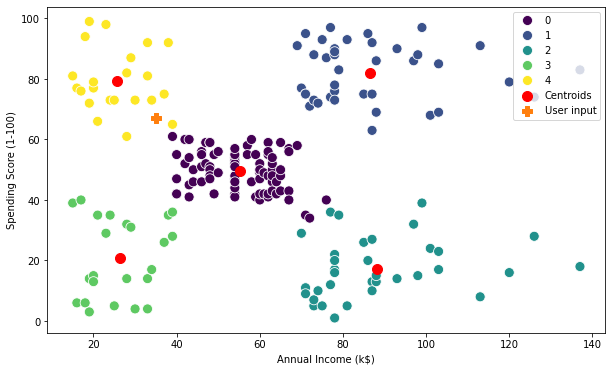

<Figure size 1440x864 with 0 Axes>

In [36]:
math.figure(figsize=(10, 6))
sns.scatterplot(x=mall["Annual Income (k$)"],y=mall["Spending Score (1-100)"],hue=model2.labels_,palette="viridis",s=100)

math.scatter(model2.cluster_centers_[:,0],model2.cluster_centers_[:,1],s=100,c='red',label="Centroids")
math.scatter(user_frame["Annual Income (k$)"],user_frame["Spending Score (1-100)"],marker='P',label="User input",s=100)

math.legend(loc="upper right")
math.figure(figsize=(20, 12))